Index(['wavePeriodMin', 'globalIdLocal', 'totalSeaMax', 'waveHighMax',
       'waveHighMin', 'longitude', 'wavePeriodMax', 'latitude', 'totalSeaMin',
       'sstMax', 'predWaveDir', 'sstMin'],
      dtype='object')
   wavePeriodMin  globalIdLocal  totalSeaMax waveHighMax waveHighMin  \
0            4.7        2320126          1.0         0.8         0.6   
1            5.2        3420226          2.5         2.2         1.1   
2            5.4        3470126          2.0         1.8         1.0   
3            4.3        2310326          0.5         0.6         0.5   
4            7.0        1130826          1.5         1.7         1.1   
5            5.9        3480226          2.0         1.9         1.3   
6            6.6        1060526          2.0         1.8         1.2   
7            1.9        1080526          0.5         0.4         0.2   
8            5.1        1111026          1.5         1.3         0.8   
9            7.1        1160926          2.0         1.8         

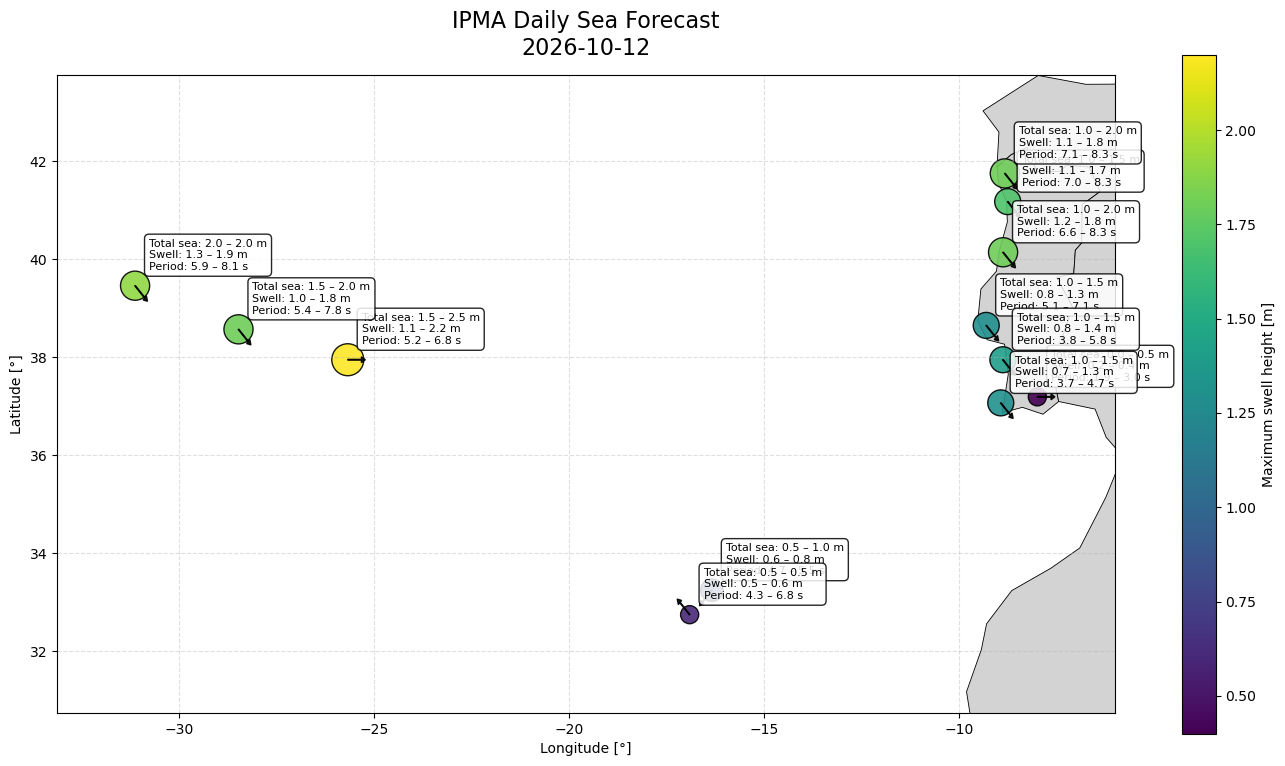

In [ ]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point


# ============================================================
# IPMA forecast
# ============================================================

URL = (
    "https://api.ipma.pt/open-data/forecast/oceanography/"
    "daily/hp-daily-sea-forecast-day0.json"
)

response = requests.get(URL)
response.raise_for_status()

data = response.json()


# ============================================================
# Convert forecast data to DataFrame
# ============================================================

df = pd.DataFrame(data["data"])

print(df.columns)
print(df)


# ============================================================
# Convert numerical columns
# ============================================================

numeric_columns = [
    "latitude",
    "longitude",

    "wavePeriodMin",
    "wavePeriodMax",

    "waveHighMin",
    "waveHighMax",

    "totalSeaMin",
    "totalSeaMax",

    "sstMin",
    "sstMax",
]

for column in numeric_columns:

    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )


# ============================================================
# Create GeoDataFrame
# ============================================================

geometry = [
    Point(lon, lat)
    for lon, lat in zip(
        df["longitude"],
        df["latitude"]
    )
]

gdf = gpd.GeoDataFrame(
    df,
    geometry=geometry,
    crs="EPSG:4326"
)


# ============================================================
# Load Natural Earth map
# ============================================================

world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/"
    "110m_cultural/ne_110m_admin_0_countries.zip"
)

# Reproject to a metric CRS
# This isn't essential for the points, but makes the
# geographic plotting more robust.

world = world.to_crs("EPSG:4326")


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 10)
)


# ------------------------------------------------------------
# Countries / coastline
# ------------------------------------------------------------

world.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=0.6
)


# ============================================================
# Forecast points
# ============================================================

# Marker size based on maximum total sea height

marker_size = (
    80
    + 180 * gdf["totalSeaMax"].fillna(0)
)


gdf.plot(
    ax=ax,

    column="waveHighMax",

    cmap="viridis",

    markersize=marker_size,

    edgecolor="black",

    linewidth=1,

    alpha=0.9,

    legend=True,

    legend_kwds={
        "label": "Maximum swell height [m]",
        "shrink": 0.7,
    },
)


# ============================================================
# Wave/swell direction
# ============================================================

# Compass direction → degrees
#
# 0   = North
# 90  = East
# 180 = South
# 270 = West

direction_angles = {
    "N": 0,
    "NE": 45,
    "E": 90,
    "SE": 135,
    "S": 180,
    "SW": 225,
    "W": 270,
    "NW": 315,
}


gdf["direction_deg"] = (
    gdf["predWaveDir"]
    .map(direction_angles)
)


# ------------------------------------------------------------
# Arrow length
# ------------------------------------------------------------

arrow_length = 0.45


for _, row in gdf.iterrows():

    angle = np.deg2rad(
        row["direction_deg"]
    )

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # predWaveDir is the direction the waves COME FROM.
    #
    # We want the arrow to point in the direction
    # the swell is TRAVELLING TO.
    #
    # Therefore reverse the vector.
    # --------------------------------------------------------

    dx = -np.sin(angle) * arrow_length
    dy = -np.cos(angle) * arrow_length


    ax.arrow(
        row["longitude"],
        row["latitude"],

        dx,
        dy,

        width=0.015,

        head_width=0.12,

        head_length=0.10,

        length_includes_head=True,

        color="black",

        alpha=0.9,

        zorder=5,
    )


# ============================================================
# Information boxes
# ============================================================

for _, row in gdf.iterrows():

    # --------------------------------------------------------
    # Format values
    # --------------------------------------------------------

    total_sea = (
        f"{row['totalSeaMin']:.1f}"
        f" - "
        f"{row['totalSeaMax']:.1f}"
    )

    swell = (
        f"{row['waveHighMin']:.1f}"
        f" - "
        f"{row['waveHighMax']:.1f}"
    )

    period = (
        f"{row['wavePeriodMin']:.1f}"
        f" - "
        f"{row['wavePeriodMax']:.1f}"
    )

    sst = (
        f"{row['sstMin']:.1f}"
        f" - "
        f"{row['sstMax']:.1f}"
    )


    # --------------------------------------------------------
    # Location name
    # --------------------------------------------------------

    location = row.get(
        "local",
        row["globalIdLocal"]
    )


    # --------------------------------------------------------
    # Text
    # --------------------------------------------------------

    text = (
        f"Total sea: {total_sea} m\n"
        f"Swell: {swell} m\n"
        f"Period: {period} s"
    )


    # --------------------------------------------------------
    # Place text next to point
    # --------------------------------------------------------

    ax.annotate(
        text,

        xy=(
            row["longitude"],
            row["latitude"]
        ),

        xytext=(
            10,
            10
        ),

        textcoords="offset points",

        fontsize=8,

        ha="left",

        va="bottom",

        bbox=dict(
            boxstyle="round,pad=0.4",

            facecolor="white",

            edgecolor="black",

            alpha=0.85,
        ),

        zorder=10,
    )


# ============================================================
# Map limits
# ============================================================

margin = 2.0

ax.set_xlim(
    gdf["longitude"].min() - margin,
    gdf["longitude"].max() + margin
)

ax.set_ylim(
    gdf["latitude"].min() - margin,
    gdf["latitude"].max() + margin
)


# ============================================================
# Labels
# ============================================================

ax.set_xlabel(
    "Longitude [°]"
)

ax.set_ylabel(
    "Latitude [°]"
)


# ============================================================
# Title
# ============================================================

ax.set_title(
    "IPMA Daily Sea Forecast\n"
    f"{data['forecastDate']}",
    fontsize=16,
    pad=15,
)


# ============================================================
# Grid
# ============================================================

ax.grid(
    True,
    linestyle="--",
    alpha=0.4
)


# ============================================================
# Final layout
# ============================================================

plt.tight_layout()

plt.show()

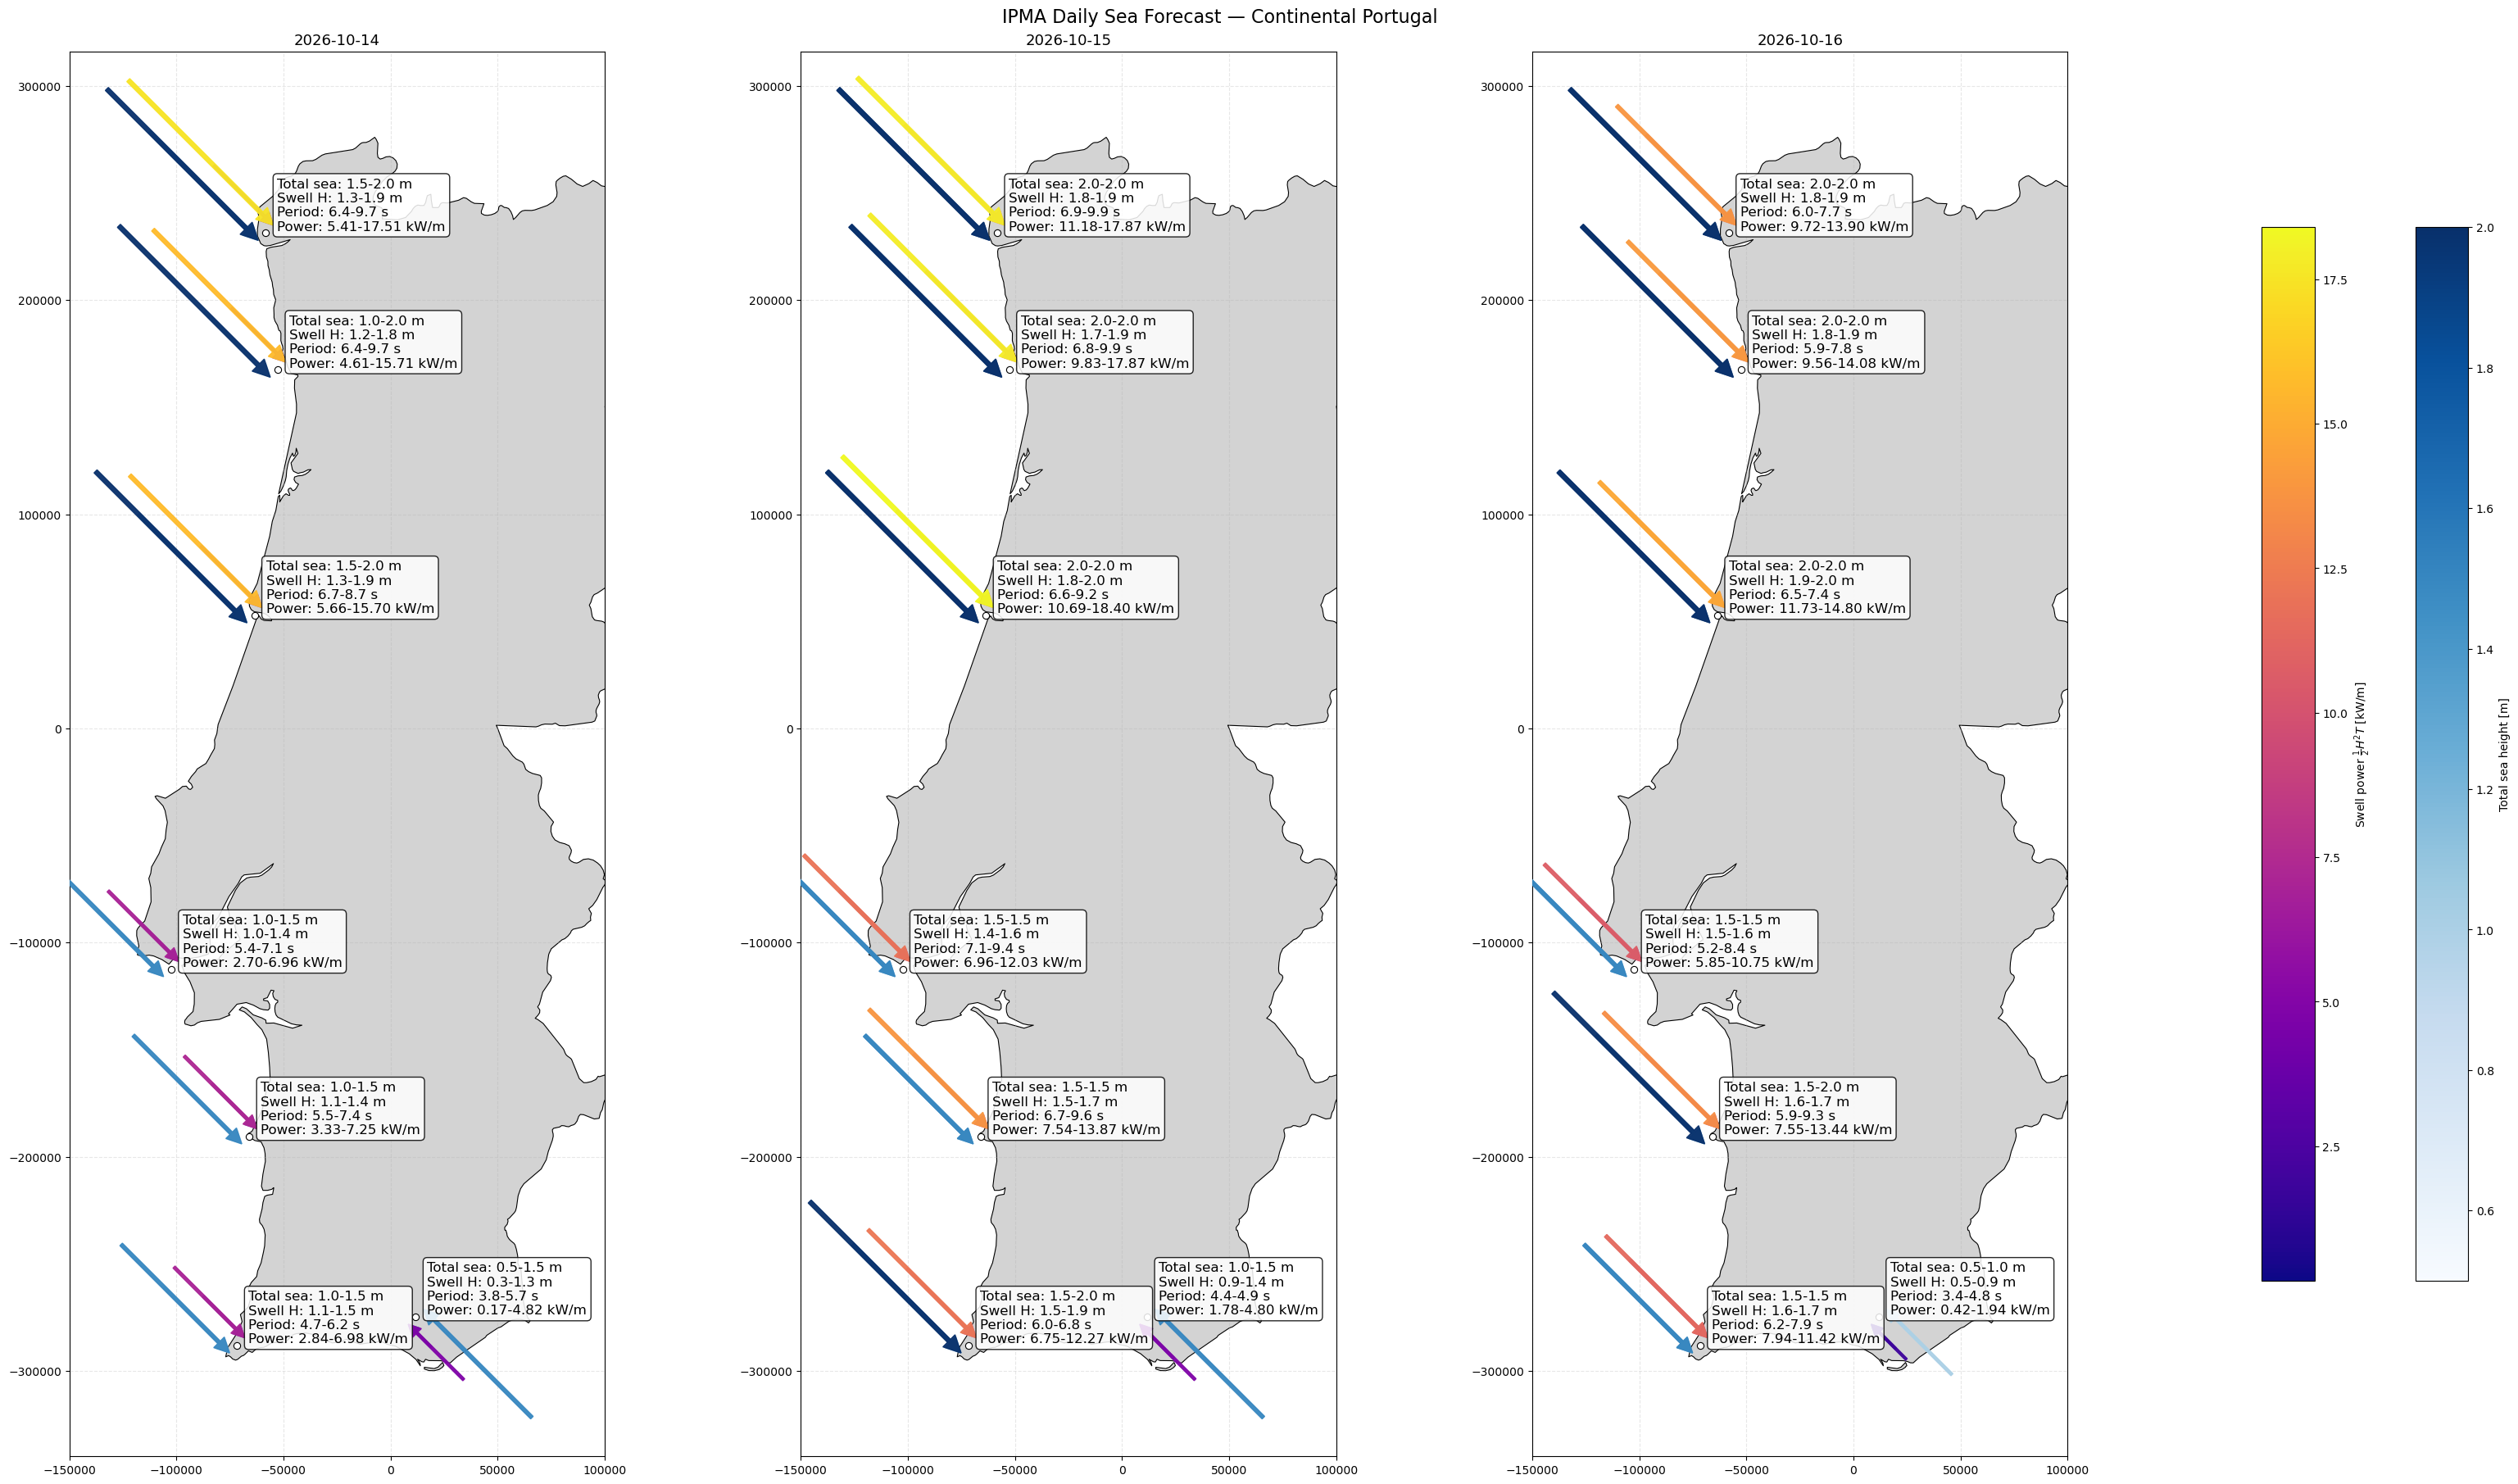

In [47]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Configuration
BASE_URL = "https://api.ipma.pt/open-data/forecast/oceanography/daily/hp-daily-sea-forecast-day{}.json"
DAYS = [0, 1, 2]

TOTAL_ARROW_MIN = 15_000  # Minimum arrow length [m]
TOTAL_ARROW_MAX = 100_000 # Maximum arrow length [m]
SWELL_ARROW_MIN = 15_000  # Minimum arrow length [m]
SWELL_ARROW_MAX = 100_000 # Maximum arrow length [m]
ARROW_OFFSET = 5e3     # Offset between total-sea and swell arrows [m]

MIN_ARROW_WIDTH = 1_000
MAX_ARROW_WIDTH = 2_000
MIN_HEAD_WIDTH = 5_000
MAX_HEAD_WIDTH = 8_000
MIN_HEAD_LENGTH = 5_000
MAX_HEAD_LENGTH = 8_000

MAP_MARGIN = 40_000

direction_angles = {"N": 0, "NE": 45, "E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "NW": 315}

def direction_vector(direction):
    angle = np.deg2rad(direction_angles[direction])
    return -np.sin(angle), -np.cos(angle)

def scaled_length(value, vmin, vmax, length_min, length_max):
    if vmax <= vmin:
        return (length_min + length_max) / 2
    return length_min + np.clip((value - vmin) / (vmax - vmin), 0, 1) * (length_max - length_min)

# Download forecasts
forecasts = []
for day in DAYS:
    response = requests.get(BASE_URL.format(day), timeout=30)
    response.raise_for_status()
    forecast = response.json()
    data = pd.DataFrame(forecast["data"])
    data["forecast_day"] = day
    data["forecast_date"] = forecast["forecastDate"]
    forecasts.append(data)

df = pd.concat(forecasts, ignore_index=True)

# Convert numerical columns
numeric_columns = [
    "latitude", "longitude", "wavePeriodMin", "wavePeriodMax",
    "waveHighMin", "waveHighMax", "totalSeaMin", "totalSeaMax",
    "sstMin", "sstMax"
]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=["latitude", "longitude", "totalSeaMin", "totalSeaMax"])

# Keep continental Portugal forecast points only
df = df[ df.longitude.between(-10.0, -6.0) & df.latitude.between(36.5, 42.5)].copy()

# Swell power [kW/m], using the supplied wave height and period
df["swellPowerMin"] = 0.5 * df["waveHighMin"]**2 * df["wavePeriodMin"]
df["swellPowerMax"] = 0.5 * df["waveHighMax"]**2 * df["wavePeriodMax"]

# Forecast points
gdf = gpd.GeoDataFrame( df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs("EPSG:3763")

# Detailed country polygons; retain mainland Portugal only
world = gpd.read_file(    "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip")
portugal = world[world["ADMIN"] == "Portugal"].to_crs("EPSG:3763")
portugal = portugal.explode(index_parts=False)
portugal = portugal[    portugal.geometry.centroid.x.between(-200_000, 200_000)].copy()

# Keep only the largest Portuguese polygon (mainland)
portugal = portugal.loc[[portugal.geometry.area.idxmax()]]

# Colour scales shared across days
total_norm = Normalize(df.totalSeaMin.min(), df.totalSeaMax.max())
swell_norm = Normalize(df.swellPowerMin.min(), df.swellPowerMax.max())
total_cmap = plt.cm.Blues
swell_cmap = plt.cm.plasma

# Arrow length ranges use the global data ranges
total_min, total_max = df.totalSeaMin.min(), df.totalSeaMax.max()
swell_min, swell_max = df.swellPowerMin.min(), df.swellPowerMax.max()

# Figure
fig, axes = plt.subplots(1, 3, figsize=(32, 18), constrained_layout=True)

for ax, day in zip(axes, DAYS):
    day_data = gdf[gdf.forecast_day == day]

    portugal.plot(ax=ax, facecolor="lightgrey", edgecolor="black", linewidth=0.8, zorder=1)
    day_data.plot(ax=ax, color="white", edgecolor="black", linewidth=0.8, markersize=35, zorder=5)

    for _, row in day_data.iterrows():
        dx, dy = direction_vector(row.predWaveDir)
        px, py = row.geometry.x, row.geometry.y

        # Total-sea arrows: length and colour represent total sea height
        x, y = px + dy * ARROW_OFFSET, py - dx * ARROW_OFFSET
        for value, alpha in [(row.totalSeaMin, 0.75), (row.totalSeaMax, 0.95)]:
            length = scaled_length(value, total_min, total_max, TOTAL_ARROW_MIN, TOTAL_ARROW_MAX)
            width = scaled_length(value, total_min, total_max, MIN_ARROW_WIDTH, MAX_ARROW_WIDTH)
            head_width = scaled_length(value, total_min, total_max, MIN_HEAD_WIDTH, MAX_HEAD_WIDTH)
            head_length = scaled_length(value, total_min, total_max, MIN_HEAD_LENGTH, MAX_HEAD_LENGTH)
            ax.arrow(x - dx * length, y - dy * length,
            dx * length, dy * length,
            width=width, head_width=head_width,
            head_length=head_length, length_includes_head=True,
            color=total_cmap(total_norm(value)), alpha=alpha, zorder=6)

        # Swell arrows: length and colour represent swell power
        x, y = px - dy * ARROW_OFFSET, py + dx * ARROW_OFFSET
        for power, alpha in [(row.swellPowerMin, 0.75), (row.swellPowerMax, 0.95)]:
            if pd.isna(power):
                continue
            length = scaled_length(power, swell_min, swell_max, SWELL_ARROW_MIN, SWELL_ARROW_MAX)
            width = scaled_length(power, swell_min, swell_max, MIN_ARROW_WIDTH, MAX_ARROW_WIDTH)
            head_width = scaled_length(power, swell_min, swell_max, MIN_HEAD_WIDTH, MAX_HEAD_WIDTH)
            head_length = scaled_length(power, swell_min, swell_max, MIN_HEAD_LENGTH, MAX_HEAD_LENGTH)
            ax.arrow( x - dx * length, y - dy * length, dx * length, dy * length, width=width, head_width=head_width, head_length=head_length, length_includes_head=True, color=swell_cmap(swell_norm(power)), alpha=alpha, zorder=7)

        # Information box
        text = (
            f"Total sea: {row.totalSeaMin:.1f}-{row.totalSeaMax:.1f} m\n"
            f"Swell H: {row.waveHighMin:.1f}-{row.waveHighMax:.1f} m\n"
            f"Period: {row.wavePeriodMin:.1f}-{row.wavePeriodMax:.1f} s\n"
            f"Power: {row.swellPowerMin:.2f}-{row.swellPowerMax:.2f} kW/m"
        )
        ax.annotate(text, xy=(px, py), xytext=(10, 0), textcoords="offset points",
                    fontsize=12, ha="left", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                              edgecolor="black", alpha=0.85), zorder=10)

    # Zoom to mainland Portugal and forecast locations
    minx, miny, maxx, maxy = portugal.total_bounds
    ax.set_xlim(-150e3, 100e3)
    ax.set_ylim(miny - MAP_MARGIN, maxy + MAP_MARGIN)
    ax.set_aspect("equal")
    ax.set_title(day_data.forecast_date.iloc[0], fontsize=13)
    ax.grid(True, linestyle="--", alpha=0.3)

# Colour bars
total_sm = ScalarMappable(norm=total_norm, cmap=total_cmap)
total_sm.set_array([])
fig.colorbar(total_sm, ax=axes, location="right", shrink=0.75, pad=0.02, label="Total sea height [m]")

swell_sm = ScalarMappable(norm=swell_norm, cmap=swell_cmap)
swell_sm.set_array([])
fig.colorbar(swell_sm, ax=axes, location="right", shrink=0.75, pad=0.08, label=r"Swell power $\frac{1}{2}H^2T$ [kW/m]")

fig.suptitle("IPMA Daily Sea Forecast — Continental Portugal", fontsize=16)
plt.show()